# Experiment 6: Simple Genetic Algorithm
**Aim:** To create a simple Genetic Algorithm by combining selection, crossover and mutation operations using Python.

**Problem:** Maximise  f(x) = x·sin(10πx) + 2  for x ∈ [−1, 2]  (a multimodal function).

**GA design:** binary encoding (22 bits) · tournament selection · single-point crossover · bit-flip mutation · elitism.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt

random.seed(10); np.random.seed(10)

# ---- Parameters ----
N_BITS, LOW, HIGH = 22, -1.0, 2.0
POP_SIZE, N_GEN = 50, 60
PC, PM, TSIZE, ELITE = 0.8, 0.01, 3, 2

In [2]:
def decode(ind):
    return LOW + int("".join(map(str, ind)), 2) * (HIGH - LOW) / (2 ** N_BITS - 1)

def fitness(ind):
    x = decode(ind)
    return x * np.sin(10 * np.pi * x) + 2.0

def init_population():
    return [[random.randint(0, 1) for _ in range(N_BITS)] for _ in range(POP_SIZE)]

def tournament(pop, fit):
    idx = max(random.sample(range(len(pop)), TSIZE), key=lambda i: fit[i])
    return pop[idx][:]

def crossover(a, b):
    if random.random() < PC:
        pt = random.randint(1, N_BITS - 1)
        return a[:pt] + b[pt:], b[:pt] + a[pt:]
    return a[:], b[:]

def mutate(ind):
    return [1 - g if random.random() < PM else g for g in ind]

In [3]:
def run_ga():
    pop = init_population()
    best_hist, avg_hist = [], []
    best_ind, best_fit = None, -np.inf
    for gen in range(N_GEN):
        fit = [fitness(i) for i in pop]
        gbest = int(np.argmax(fit))
        if fit[gbest] > best_fit:
            best_fit, best_ind = fit[gbest], pop[gbest][:]
        best_hist.append(max(fit)); avg_hist.append(np.mean(fit))

        # elitism
        order = sorted(range(len(pop)), key=lambda i: fit[i], reverse=True)
        new_pop = [pop[i][:] for i in order[:ELITE]]

        while len(new_pop) < POP_SIZE:
            p1, p2 = tournament(pop, fit), tournament(pop, fit)
            c1, c2 = crossover(p1, p2)
            new_pop += [mutate(c1), mutate(c2)]
        pop = new_pop[:POP_SIZE]
    return best_ind, best_fit, best_hist, avg_hist

best_ind, best_fit, best_hist, avg_hist = run_ga()
print("Best chromosome:", "".join(map(str, best_ind)))
print(f"Best x = {decode(best_ind):.5f}")
print(f"Best f(x) = {best_fit:.5f}")

Best chromosome: 1111001011111111111111
Best x = 1.84766
Best f(x) = 3.84265


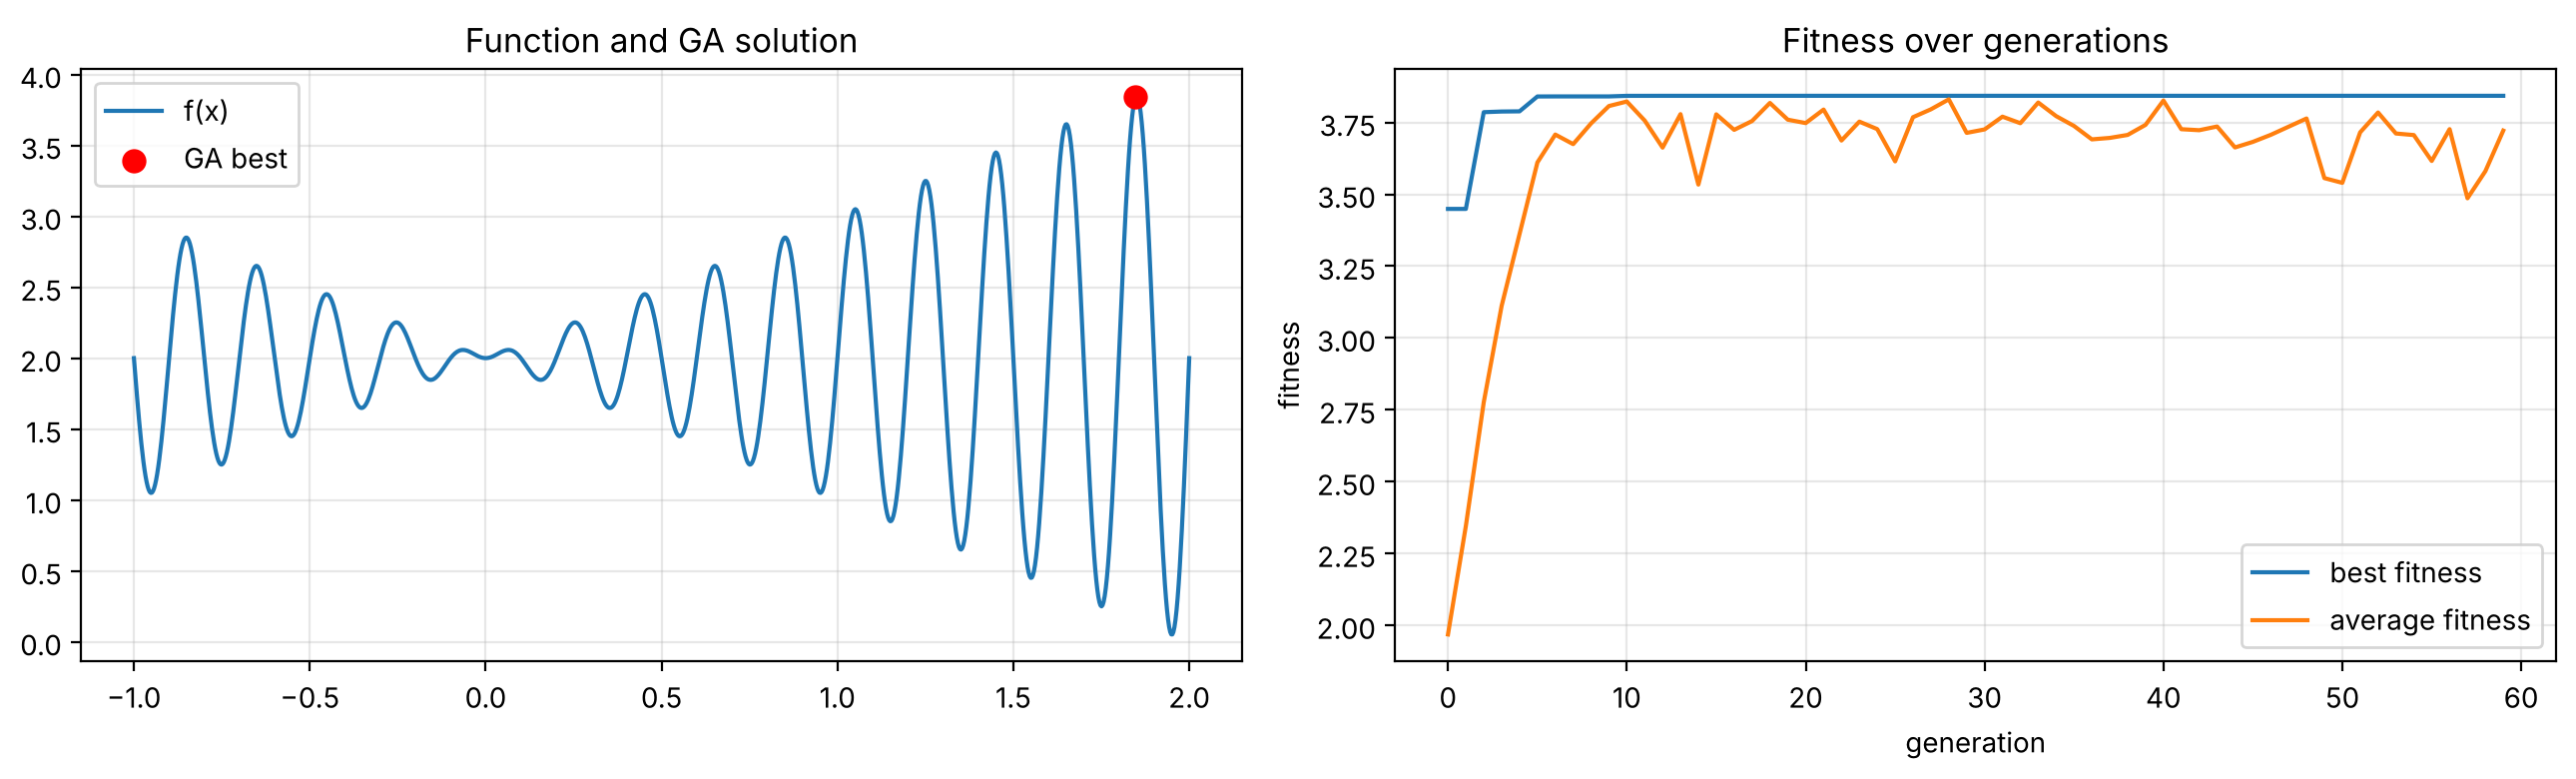

In [4]:
x = np.linspace(LOW, HIGH, 1000)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

ax[0].plot(x, x * np.sin(10 * np.pi * x) + 2, label="f(x)")
ax[0].scatter([decode(best_ind)], [best_fit], c="red", s=60, zorder=3, label="GA best")
ax[0].set_title("Function and GA solution"); ax[0].legend(); ax[0].grid(alpha=0.3)

ax[1].plot(best_hist, label="best fitness")
ax[1].plot(avg_hist, label="average fitness")
ax[1].set_xlabel("generation"); ax[1].set_ylabel("fitness")
ax[1].set_title("Fitness over generations"); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Conclusion
A complete GA (initialisation → evaluation → selection → crossover → mutation → elitist replacement) was built from scratch. The best fitness rises quickly and the average fitness approaches it, showing the population converging near the global maximum (x ≈ 1.85, f ≈ 3.85).